# Chapter 13 — Visual–inertial odometry

Companion notebook to **Chapter 13**: the smooth garden drive and its exact IMU, the visual factor with an inertial
state, the sliding-window VIO against the stereo VO, the four unobservable directions, the tilt–bias ambiguity of
straight rows, the MSCKF null-space trick, and initialisation. To stay quick it uses the first 20 s of the drive;
`examples/ch13_vio.py` runs the whole of it.

In [1]:
import sys
from pathlib import Path

ROOT = Path.cwd().parent            # the code/ directory
sys.path[:0] = [str(ROOT), str(ROOT / "examples")]

import numpy as np
import matplotlib.pyplot as plt
from vslam import imu, lie, sim, vio
from ch13_vio import setup, run_vio, errors, stereo_vo, window_hessian, CAM_RATE

np.set_printoptions(precision=4, suppress=True)
rng = np.random.default_rng(0)
# after the imports: the example scripts select the Agg backend
%matplotlib inline

## 1. The drive and its IMU

`sim.GardenMotion` gives the pose, velocity, acceleration and angular rate in closed form, so the simulated IMU is
exact. The mower rests for 2 s, accelerates, and follows the rows with smooth turns.

true biases: gyro [ 0.036  -0.0378  0.1835] deg/s, accel [ 0.0052 -0.0268  0.0181] m/s^2


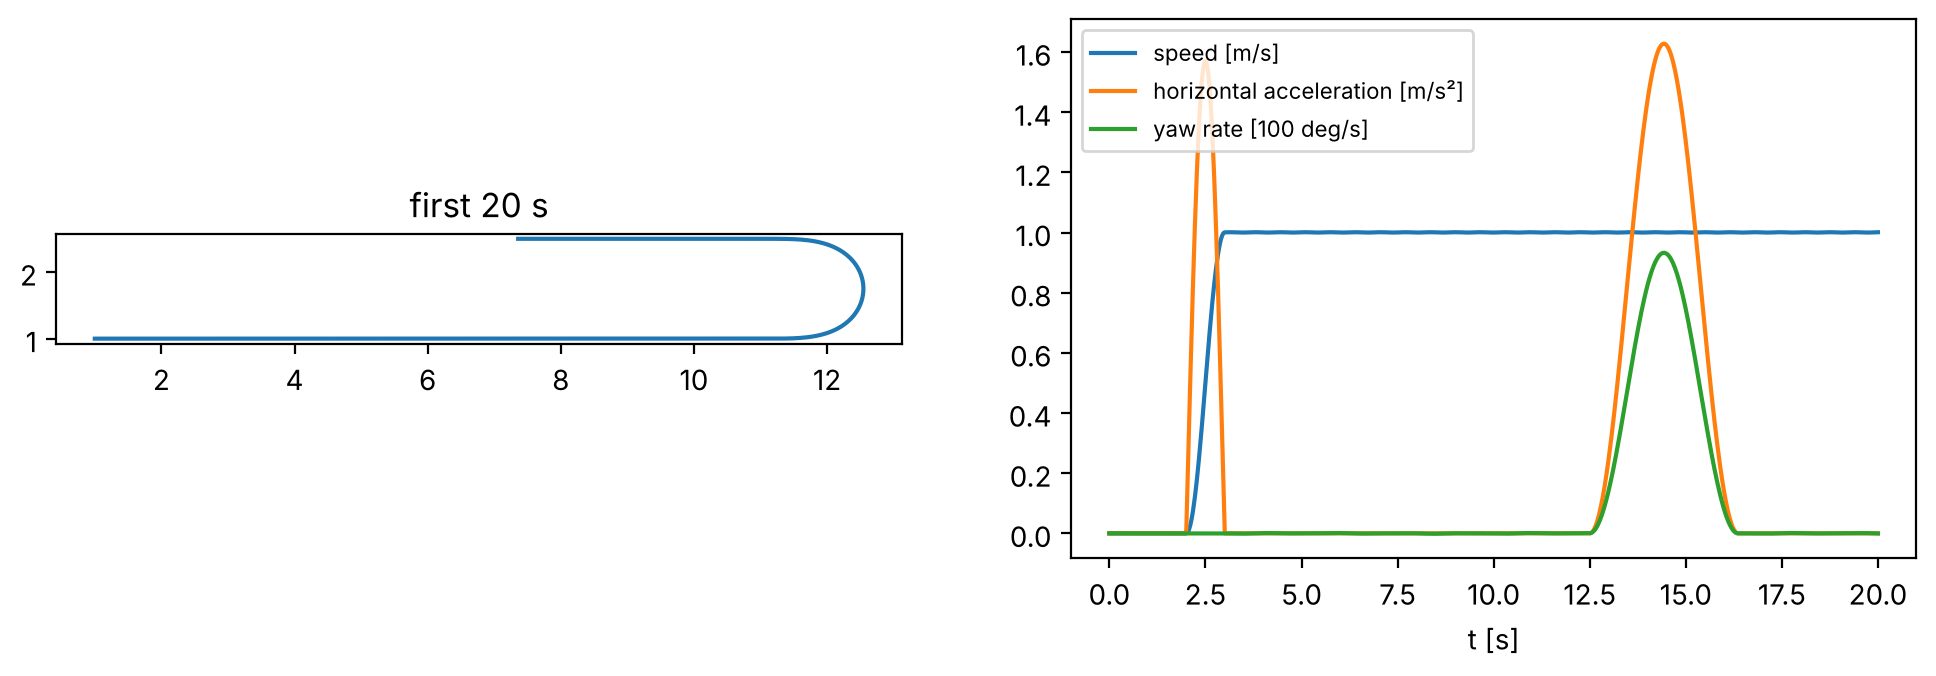

In [2]:
m, P, data, S, Tbc, ts, frames = setup()
T_end = 20.0
tt = np.linspace(0, T_end, 800)
p = np.array([m.p(t) for t in tt])
speed = [np.linalg.norm(m.v(t)) for t in tt]
lat = [np.linalg.norm(m.acc(t)[:2]) for t in tt]
fig, ax = plt.subplots(1, 2, figsize=(12, 3.5))
ax[0].plot(p[:, 0], p[:, 1]); ax[0].set_aspect("equal"); ax[0].set_title("first 20 s")
ax[1].plot(tt, speed, label="speed [m/s]"); ax[1].plot(tt, lat, label="horizontal acceleration [m/s²]")
ax[1].plot(tt, np.degrees([m.omega(t)[2] for t in tt]) / 100, label="yaw rate [100 deg/s]")
ax[1].set_xlabel("t [s]"); ax[1].legend(fontsize=8)
print(f"true biases: gyro {np.degrees(data.bg[0])} deg/s, accel {data.ba[0]} m/s^2")

## 2. The visual factor with an inertial state (Proposition 13.1)

In [3]:
R = lie.so3_exp(rng.normal(0, 0.3, 3)); pb = rng.normal(0, 1, 3)
Rc, c = R @ Tbc[:3, :3], pb + R @ Tbc[:3, 3]
X = Rc @ np.array([0.5, -0.1, 6.0]) + c
z = np.array([[420.0, 240.0, 410.0]])
r0, A, B, _ = vio.stereo_residuals(R[None], pb[None], X[None], z, Tbc, S.stereo, 0.5)
eps, num = 1e-6, np.zeros((3, 15))
for k in range(15):
    d = np.zeros(15); d[k] = eps
    s = vio.boxplus(vio.KFState(R, np.zeros(3), pb, np.zeros(3), np.zeros(3)), d)
    num[:, k] = (vio.stereo_residuals(s.R[None], s.p[None], X[None], z, Tbc, S.stereo, 0.5)[0][0] - r0[0]) / eps
print("max |analytic - numeric|:", np.abs(num - A[0]).max())
print("columns for velocity and biases are zero:", np.abs(A[0][:, 3:6]).max(), np.abs(A[0][:, 9:]).max())

max |analytic - numeric|: 0.00011472713727300743
columns for velocity and biases are zero: 0.0 0.0


## 3. VIO against stereo VO on the first 20 s

VIO: 72 keyframes in 12.0 s; final error 1.0 cm (VO 30.9 cm)


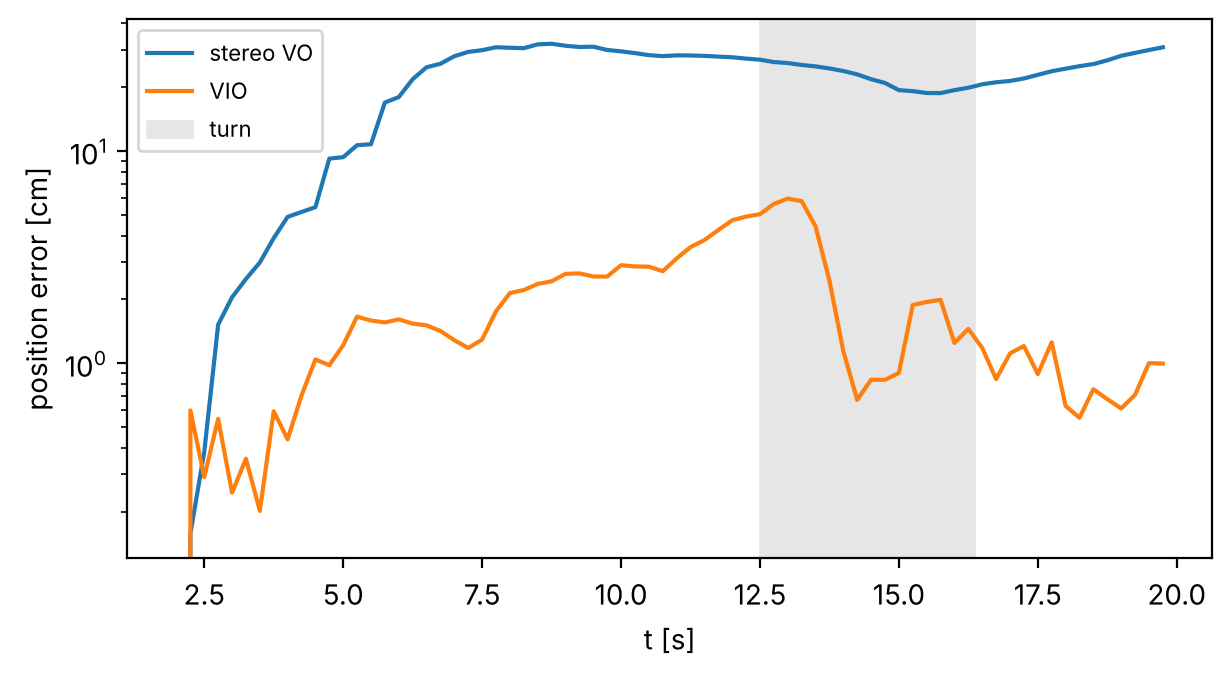

In [4]:
short = frames[:int(T_end * CAM_RATE)]
V, est = run_vio(m, P, data, S, Tbc, ts[:len(short)], short)
vo_est = stereo_vo(m, S, Tbc, ts[:len(short)], short)
tv = np.array([t for t, _ in est]); ev, tilt, yaw = errors(m, [(t, s.R, s.p) for t, s in est])
to = np.array([t for t, _, _ in vo_est]); eo, _, _ = errors(m, vo_est)
plt.figure(figsize=(7, 3.5))
plt.semilogy(to, 100 * eo, label="stereo VO"); plt.semilogy(tv, 100 * ev, label="VIO")
plt.axvspan(12.5, 16.36, color="0.9", label="turn"); plt.xlabel("t [s]"); plt.ylabel("position error [cm]"); plt.legend(fontsize=8)
print(f"VIO: {len(est)} keyframes in {V.runtime:.1f} s; final error {100 * ev[-1]:.1f} cm (VO {100 * eo[-1]:.1f} cm)")

## 4. Four unobservable directions (Theorem 13.3)

The Gauss–Newton Hessian of the window without prior annihilates the translations and the rotation about gravity.
A rotation about a horizontal axis is not annihilated.

In [5]:
Hs, W, Vb, _, _, pid = V.normal_equations(use_prior=False)
n, Pn = len(Hs), len(pid)
H = np.zeros((n + 3 * Pn, n + 3 * Pn))
H[:n, :n], H[:n, n:], H[n:, :n] = Hs, W, W.T
for j in range(Pn):
    H[n + 3 * j:n + 3 * j + 3, n + 3 * j:n + 3 * j + 3] = Vb[j]
U = vio.gauge_directions(V.kfs, V.points); U /= np.linalg.norm(U, axis=0)
sci = lambda x: " ".join(f"{v:.1e}" for v in x)
print("|H u| / |H| for x, y, z, yaw:", sci(np.linalg.norm(H @ U, axis=0) / np.linalg.norm(H, 2)))
ev = np.sort(np.linalg.eigvalsh(window_hessian(V)))
print("smallest eigenvalues of the reduced Hessian / largest:", sci(ev[:7] / ev[-1]))
ex = np.array([1.0, 0, 0]); u = np.zeros(len(H))           # roll, for comparison
for k, s in enumerate(V.kfs):
    u[15*k:15*k+3], u[15*k+3:15*k+6], u[15*k+6:15*k+9] = s.R.T @ ex, np.cross(ex, s.v), s.R.T @ np.cross(ex, s.p)
for j, i in enumerate(pid):
    u[n+3*j:n+3*j+3] = np.cross(ex, V.points[i])
print("|H u| / |H| for roll:", sci([np.linalg.norm(H @ u) / np.linalg.norm(u) / np.linalg.norm(H, 2)]))

|H u| / |H| for x, y, z, yaw: 1.0e-18 1.4e-18 8.3e-19 2.7e-18


smallest eigenvalues of the reduced Hessian / largest: -1.9e-17 3.3e-18 2.6e-17 3.7e-17 3.8e-12 9.4e-12 2.6e-07


|H u| / |H| for roll: 3.1e-06


## 5. Tilt and accelerometer bias (Proposition 13.4)

Until the first turn the accelerometer bias error and the tilt error trade against each other ($b \approx g\,\delta\theta$);
the turn separates them.

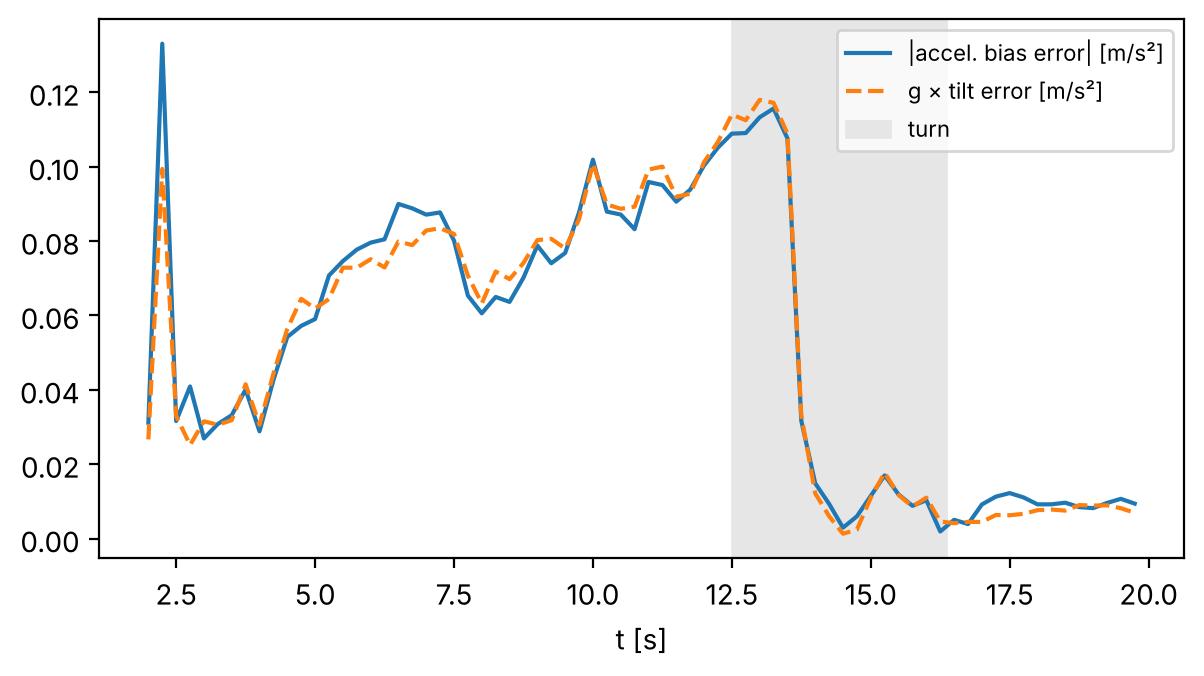

In [6]:
ba_err = [np.linalg.norm(s.ba - data.ba[int(round(t / P.dt))]) for t, s in est]
fig, ax = plt.subplots(figsize=(7, 3.5))
ax.plot(tv, ba_err, label="|accel. bias error| [m/s²]")
ax.plot(tv, np.radians(tilt) * 9.81, "--", label="g × tilt error [m/s²]")
ax.axvspan(12.5, 16.36, color="0.9", label="turn"); ax.set_xlabel("t [s]"); ax.legend(fontsize=8)

## 6. The MSCKF null-space projection (Proposition 13.5)

In [7]:
m_obs, nx = 8, 15
Hx, Hf, r = rng.normal(size=(m_obs, nx)), rng.normal(size=(m_obs, 3)), rng.normal(size=m_obs)
Ho, ro = vio.msckf_project(Hx, Hf, r)
S_info = Hx.T @ Hx - Hx.T @ Hf @ np.linalg.solve(Hf.T @ Hf, Hf.T @ Hx)
print("rows kept:", Ho.shape[0], "of", m_obs)
print("projected information equals the Schur complement:", np.allclose(Ho.T @ Ho, S_info))

rows kept: 5 of 8
projected information equals the Schur complement: True


## 7. Initialisation (Propositions 13.6 and 13.7)

In [8]:
n0 = int(round(m.still / P.dt))
R0, bg0 = vio.static_init(data.gyro[:n0], data.accel[:n0])
up = np.array([0, 0, 1.0])
print(f"static: gyro bias error {np.degrees(np.linalg.norm(bg0 - data.bg[:n0].mean(0))):.4f} deg/s, "
      f"tilt error {np.degrees(np.arccos((R0.T @ up) @ (m.R(m.still).T @ up))):.2f} deg "
      f"(|horizontal accel. bias| / g = {np.degrees(np.linalg.norm(data.ba[0][:2]) / 9.81):.2f} deg)")
# dynamic: from noise-free motion with known poses, 3 s after the ramp
k = np.arange(int(3.5 / P.dt), int(6.5 / P.dt) + 1, 25)
Rs, ps = [m.R(i * P.dt) for i in k], [m.p(i * P.dt) for i in k]
pres = [imu.Preintegration.from_data(data, np.zeros(3), np.zeros(3), P, a, b) for a, b in zip(k[:-1], k[1:])]
bg = vio.gyro_bias_from_rotations(Rs, pres)
pres = [imu.Preintegration.from_data(data, bg, np.zeros(3), P, a, b) for a, b in zip(k[:-1], k[1:])]
g, v = vio.align_gravity_velocity(Rs, ps, pres)
print(f"dynamic: gyro bias error {np.degrees(np.linalg.norm(bg - data.bg[k[len(k)//2]])):.4f} deg/s, "
      f"gravity {g}, velocity error max {np.abs(v - np.array([m.v(i * P.dt) for i in k])).max():.3f} m/s")

static: gyro bias error 0.0124 deg/s, tilt error 0.16 deg (|horizontal accel. bias| / g = 0.16 deg)


dynamic: gyro bias error 0.0167 deg/s, gravity [-0.0082  0.0312 -9.8235], velocity error max 0.002 m/s


## Exercises

1. Run the VIO with `window=4` and `window=16`. How do accuracy and run time change?
2. Delay the camera by 5 ms (`setup(td=0.005)`) and plot the error: where does it grow? Compare with
   $t_d\,\dot\psi\,d$ (Proposition 13.8).
3. Remove the bumps and the sway (`sim.GardenMotion(bump=0, sway_deg=0)`) and look again at the smallest eigenvalues
   on a straight row: what happens to the two weak directions?